<a href="https://colab.research.google.com/github/Pineapp1e-pie/recommender-systems-research/blob/main/NIR_Recommender_Systems.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
# Основные библиотеки для работы с данными
import pandas as pd
import numpy as np

# Инструменты для машинного обучения
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.model_selection import train_test_split

# Статистические методы
from scipy.stats import wilcoxon

# Визуализация
import matplotlib.pyplot as plt
import seaborn as sns

# Дополнительные инструменты
import random
import os
import zipfile
import urllib.request

# Фиксируем начальное состояние генераторов случайных чисел
SEED = 42
np.random.seed(SEED)
random.seed(SEED)

print("Все библиотеки успешно подключены!")

Все библиотеки успешно подключены!


In [4]:
# Загружаем MovieLens 100K
url = "https://files.grouplens.org/datasets/movielens/ml-100k.zip"

urllib.request.urlretrieve(url, "ml-100k.zip")

with zipfile.ZipFile("ml-100k.zip", "r") as zip_ref:
    zip_ref.extractall(".")

# Читаем файл с оценками
ratings = pd.read_csv(
    "ml-100k/u.data",
    sep="\t",
    names=["user_id", "movie_id", "rating", "timestamp"]
)

# Проверка данных
print("Размер датасета:", ratings.shape)
print("Количество пользователей:", ratings["user_id"].nunique())
print("Количество фильмов:", ratings["movie_id"].nunique())

ratings.head()

Размер датасета: (100000, 4)
Количество пользователей: 943
Количество фильмов: 1682


,user_id,movie_id,rating,timestamp
0,196,242,3,881250949
1,186,302,3,891717742
2,22,377,1,878887116
3,244,51,2,880606923
4,166,346,1,886397596


In [5]:
# Основная информация о датасете
print("Информация о данных:")
ratings.info()

# Статистика оценок
print("\nСтатистика оценок:")
print(ratings["rating"].describe())

# Распределение оценок
print("\nКоличество оценок каждого типа:")
print(ratings["rating"].value_counts().sort_index())

Информация о данных:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 4 columns):
 #   Column     Non-Null Count   Dtype
---  ------     --------------   -----
 0   user_id    100000 non-null  int64
 1   movie_id   100000 non-null  int64
 2   rating     100000 non-null  int64
 3   timestamp  100000 non-null  int64
dtypes: int64(4)
memory usage: 3.1 MB

Статистика оценок:
count    100000.000000
mean          3.529860
std           1.125674
min           1.000000
25%           3.000000
50%           4.000000
75%           4.000000
max           5.000000
Name: rating, dtype: float64

Количество оценок каждого типа:
rating
1     6110
2    11370
3    27145
4    34174
5    21201
Name: count, dtype: int64


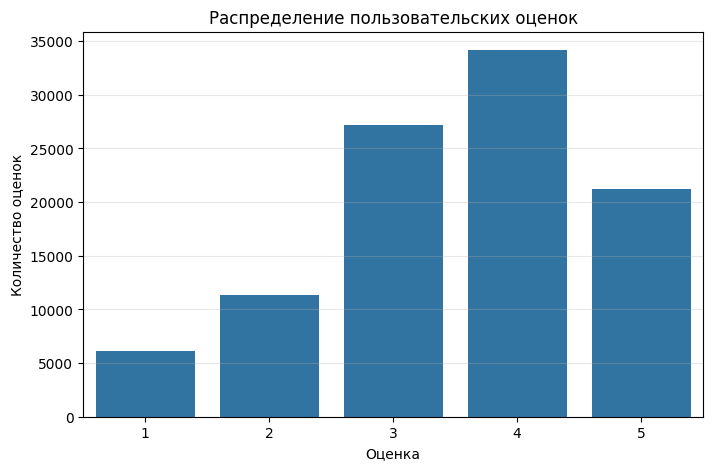

In [6]:
plt.figure(figsize=(8, 5))

sns.countplot(data=ratings, x="rating")

plt.title("Распределение пользовательских оценок")
plt.xlabel("Оценка")
plt.ylabel("Количество оценок")
plt.grid(axis="y", alpha=0.3)

plt.show()

In [7]:
# Разделяем данные отдельно для каждого пользователя

train_parts = []
test_parts = []

for user_id, user_data in ratings.groupby("user_id"):
    user_train, user_test = train_test_split(
        user_data,
        test_size=0.2,
        random_state=SEED
    )

    train_parts.append(user_train)
    test_parts.append(user_test)

# Объединяем части обратно
train_full = pd.concat(train_parts).reset_index(drop=True)
test = pd.concat(test_parts).reset_index(drop=True)

# Оставляем пользователей, у которых в тестовой выборке
# есть хотя бы один релевантный фильм (оценка >= 4)
relevant_test = test[test["rating"] >= 4]

eval_users = relevant_test["user_id"].unique()

# Выводим результаты
print("Обучающая выборка:", len(train_full))
print("Тестовая выборка:", len(test))
print("Пользователей в исходном датасете:", ratings["user_id"].nunique())
print("Пользователей для оценки:", len(eval_users))
print("Релевантных оценок в тестовой выборке:", len(relevant_test))

Обучающая выборка: 79619
Тестовая выборка: 20381
Пользователей в исходном датасете: 943
Пользователей для оценки: 929
Релевантных оценок в тестовой выборке: 11270


In [8]:
# Список всех фильмов в датасете
all_movies = set(ratings["movie_id"].unique())

# Фильмы, известные каждому пользователю из обучения
train_items = (
    train_full.groupby("user_id")["movie_id"]
    .apply(set)
    .to_dict()
)

# Релевантные фильмы каждого пользователя из теста
relevant_items = (
    relevant_test.groupby("user_id")["movie_id"]
    .apply(set)
    .to_dict()
)

# Фильмы, которые пользователь ещё не оценивал
candidate_items = {
    user_id: all_movies - train_items[user_id]
    for user_id in eval_users
}

# Проверяем подготовленные данные
print("Количество всех фильмов:", len(all_movies))
print("Количество пользователей для оценки:", len(eval_users))

print("\nПример для первого пользователя:")
example_user = eval_users[0]

print("ID пользователя:", example_user)
print("Фильмов в обучении:", len(train_items[example_user]))
print("Релевантных фильмов в тесте:", len(relevant_items[example_user]))
print("Доступных фильмов для рекомендаций:", len(candidate_items[example_user]))

# Проверяем, что релевантные фильмы входят в список кандидатов
assert all(
    relevant_items[user_id].issubset(candidate_items[user_id])
    for user_id in eval_users
)

print("\nПроверка пройдена: все релевантные фильмы доступны для рекомендации.")

Количество всех фильмов: 1682
Количество пользователей для оценки: 929

Пример для первого пользователя:
ID пользователя: 1
Фильмов в обучении: 217
Релевантных фильмов в тесте: 30
Доступных фильмов для рекомендаций: 1465

Проверка пройдена: все релевантные фильмы доступны для рекомендации.


# **Реализация Popularity-based**

Это базовый алгоритм рекомендаций. Он не анализирует индивидуальные предпочтения пользователя, а предлагает фильмы, которые получили наибольшее количество оценок в обучающей выборке.

Согласно методологии нашей НИР:
- основной критерий сортировки — количество оценок фильма;
- при одинаковом количестве оценок учитывается средняя оценка;
- уже просмотренные (оценённые) пользователем фильмы исключаются;
- формируется список из 10 рекомендаций.

In [9]:
# Рассчитываем популярность фильмов по обучающей выборке
movie_popularity = (
    train_full.groupby("movie_id")
    .agg(
        rating_count=("rating", "count"),
        average_rating=("rating", "mean")
    )
    .reset_index()
)

# Сортируем фильмы:
# 1. По количеству оценок (убывание)
# 2. По средней оценке (убывание)
# 3. По ID фильма (для стабильного порядка)
movie_popularity = movie_popularity.sort_values(
    by=["rating_count", "average_rating", "movie_id"],
    ascending=[False, False, True]
)

# Общий рейтинг популярных фильмов
popularity_ranking = movie_popularity["movie_id"].tolist()

# Функция формирования рекомендаций
def recommend_popularity(user_id, top_n=10):
    candidates = candidate_items[user_id]

    recommendations = [
        movie_id
        for movie_id in popularity_ranking
        if movie_id in candidates
    ]

    return recommendations[:top_n]


# Формируем рекомендации для всех пользователей
popularity_recommendations = {
    user_id: recommend_popularity(user_id, top_n=10)
    for user_id in eval_users
}

# Проверяем результат
example_user = eval_users[0]

print("Пользователь:", example_user)
print("Рекомендованные фильмы:", popularity_recommendations[example_user])
print("Количество рекомендаций:", len(popularity_recommendations[example_user]))

# Проверяем все списки рекомендаций
assert all(
    len(recommendations) == 10
    for recommendations in popularity_recommendations.values()
)

print("\nАлгоритм Popularity-based успешно реализован!")

Пользователь: 1
Рекомендованные фильмы: [258, 294, 286, 288, 300, 117, 405, 313, 748, 318]
Количество рекомендаций: 10

Алгоритм Popularity-based успешно реализован!


#**User-based Collaborative Filtering**

In [10]:
# Внутреннее разделение обучающей выборки
tune_train_parts = []
validation_parts = []

for user_id, user_data in train_full.groupby("user_id"):
    user_train, user_validation = train_test_split(
        user_data,
        test_size=0.2,
        random_state=SEED + 1
    )

    tune_train_parts.append(user_train)
    validation_parts.append(user_validation)

# Объединяем части
tune_train = pd.concat(tune_train_parts).reset_index(drop=True)
validation = pd.concat(validation_parts).reset_index(drop=True)

# Релевантные фильмы для настройки параметров
relevant_validation = validation[
    validation["rating"] >= 4
]

validation_users = relevant_validation[
    "user_id"
].unique()

print("Данные для настройки параметров:")
print("Обучающая часть:", len(tune_train))
print("Валидационная часть:", len(validation))
print("Пользователей с релевантными фильмами:", len(validation_users))
print("Релевантных оценок:", len(relevant_validation))

# Проверяем, что внешняя тестовая выборка не изменилась
assert len(test) == 20381
assert len(train_full) == 79619

print("\nВнешняя тестовая выборка сохранена без изменений.")

Данные для настройки параметров:
Обучающая часть: 63305
Валидационная часть: 16314
Пользователей с релевантными фильмами: 925
Релевантных оценок: 9022

Внешняя тестовая выборка сохранена без изменений.


In [11]:
# Строим матрицу взаимодействий на обучающих данных
user_item_matrix = tune_train.pivot_table(
    index="user_id",
    columns="movie_id",
    values="rating"
).fillna(0)

# Рассчитываем косинусное сходство пользователей
user_similarity = cosine_similarity(user_item_matrix)

# Сохраняем результат в DataFrame
user_similarity = pd.DataFrame(
    user_similarity,
    index=user_item_matrix.index,
    columns=user_item_matrix.index
)

# Проверяем матрицу
print("Размер матрицы взаимодействий:", user_item_matrix.shape)
print("Размер матрицы сходства:", user_similarity.shape)

print("\nПример матрицы взаимодействий:")
display(user_item_matrix.iloc[:5, :5])

print("\nПример матрицы сходства:")
display(user_similarity.iloc[:5, :5])

Размер матрицы взаимодействий: (943, 1620)
Размер матрицы сходства: (943, 943)

Пример матрицы взаимодействий:


movie_id,1,2,3,4,5
user_id,,,,,
1,5.0,0.0,4.0,0.0,3.0
2,0.0,0.0,0.0,0.0,0.0
3,0.0,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,0.0,0.0
5,4.0,3.0,0.0,0.0,0.0



Пример матрицы сходства:


user_id,1,2,3,4,5
user_id,,,,,
1,1.000000,0.111648,0.052124,0.022587,0.255711
2,0.111648,1.000000,0.076783,0.000000,0.047722
3,0.052124,0.076783,1.000000,0.168688,0.000000
4,0.022587,0.000000,0.168688,1.000000,0.015097
5,0.255711,0.047722,0.000000,0.015097,1.000000


In [12]:
# Подготавливаем оценки соседей для быстрого доступа
user_ratings = (
    tune_train.groupby("user_id")
    .apply(
        lambda x: dict(zip(x["movie_id"], x["rating"]))
    )
    .to_dict()
)


def recommend_user_based(user_id, k=20, min_neighbors=2, top_n=10):
    # Проверяем наличие пользователя в матрице
    if user_id not in user_similarity.index:
        return []

    # Получаем сходство с другими пользователями
    similarities = user_similarity.loc[user_id].drop(user_id)

    # Выбираем k наиболее похожих пользователей
    neighbors = similarities.sort_values(
        ascending=False
    ).head(k)

    # Убираем пользователей с нулевым сходством
    neighbors = neighbors[neighbors > 0]

    scores = {}

    # Рассчитываем прогноз для каждого фильма-кандидата
    for movie_id in all_movies - set(user_ratings[user_id]):

        weighted_sum = 0
        similarity_sum = 0
        neighbor_count = 0

        for neighbor_id, similarity in neighbors.items():

            neighbor_movie_rating = user_ratings.get(
                neighbor_id, {}
            ).get(movie_id)

            if neighbor_movie_rating is not None:
                weighted_sum += similarity * neighbor_movie_rating
                similarity_sum += similarity
                neighbor_count += 1

        # Учитываем только фильмы с достаточным числом оценок соседей
        if neighbor_count >= min_neighbors and similarity_sum > 0:
            scores[movie_id] = weighted_sum / similarity_sum

    # Сортируем по прогнозируемой оценке
    recommendations = sorted(
        scores.items(),
        key=lambda x: (-x[1], x[0])
    )

    return [movie_id for movie_id, score in recommendations[:top_n]]

/tmp/ipykernel_2172/4077165344.py:4: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(


In [13]:
example_user = 1

user_cf_recommendations = recommend_user_based(
    example_user,
    k=20,
    min_neighbors=2,
    top_n=10
)

print("Пользователь:", example_user)
print("Рекомендации:", user_cf_recommendations)
print("Количество рекомендаций:", len(user_cf_recommendations))

Пользователь: 1
Рекомендации: [np.int64(580), np.int64(114), np.int64(134), np.int64(313), np.int64(963), np.int64(223), np.int64(50), np.int64(169), np.int64(357), np.int64(1039)]
Количество рекомендаций: 10


In [14]:
# Проверяем User-based CF для всех пользователей

user_cf_recommendations = {
    user_id: recommend_user_based(
        user_id,
        k=20,
        min_neighbors=2,
        top_n=10
    )
    for user_id in eval_users
}

# Статистика количества рекомендаций
recommendation_counts = [
    len(recs)
    for recs in user_cf_recommendations.values()
]

print("Количество пользователей:", len(user_cf_recommendations))
print("Максимальное количество рекомендаций:", max(recommendation_counts))
print("Минимальное количество рекомендаций:", min(recommendation_counts))
print("Среднее количество рекомендаций:", np.mean(recommendation_counts))

print("\nПользователей с 10 рекомендациями:",
      sum(count == 10 for count in recommendation_counts))

print("Пользователей менее чем с 10 рекомендациями:",
      sum(count < 10 for count in recommendation_counts))

Количество пользователей: 929
Максимальное количество рекомендаций: 10
Минимальное количество рекомендаций: 10
Среднее количество рекомендаций: 10.0

Пользователей с 10 рекомендациями: 929
Пользователей менее чем с 10 рекомендациями: 0


In [15]:
def calculate_ndcg(recommendations, relevant_items, k=10):
    dcg = 0.0

    for rank, movie_id in enumerate(recommendations[:k], start=1):
        if movie_id in relevant_items:
            dcg += 1 / np.log2(rank + 1)

    ideal_hits = min(len(relevant_items), k)

    idcg = sum(
        1 / np.log2(rank + 1)
        for rank in range(1, ideal_hits + 1)
    )

    return dcg / idcg if idcg > 0 else 0.0

In [16]:
# Подбираем параметры User-based CF

k_values = [10, 20, 40, 60]
min_neighbor_values = [1, 2, 3, 5]

validation_results = []

# Готовим матрицу сходства и оценки для валидационной модели
# (они уже построены на tune_train)

for k in k_values:
    for min_n in min_neighbor_values:

        scores = []

        for user_id in validation_users:

            recommendations = recommend_user_based(
                user_id,
                k=k,
                min_neighbors=min_n,
                top_n=10
            )

            relevant = set(
                relevant_validation[
                    relevant_validation["user_id"] == user_id
                ]["movie_id"]
            )

            scores.append(
                calculate_ndcg(recommendations, relevant, k=10)
            )

        mean_ndcg = np.mean(scores)

        validation_results.append({
            "k": k,
            "min_neighbors": min_n,
            "NDCG@10": mean_ndcg
        })

        print(
            f"k={k}, min_neighbors={min_n}, "
            f"NDCG@10={mean_ndcg:.4f}"
        )

# Формируем таблицу результатов
validation_results_df = pd.DataFrame(validation_results)

# Сортируем по качеству
validation_results_df = validation_results_df.sort_values(
    "NDCG@10",
    ascending=False
)

display(validation_results_df)

# Выбираем лучшую комбинацию
best_params = validation_results_df.iloc[0]

best_k = int(best_params["k"])
best_min_neighbors = int(best_params["min_neighbors"])

print("Лучшие параметры:")
print("k =", best_k)
print("min_neighbors =", best_min_neighbors)
print("NDCG@10 =", round(best_params["NDCG@10"], 4))

k=10, min_neighbors=1, NDCG@10=0.0516
k=10, min_neighbors=2, NDCG@10=0.1091
k=10, min_neighbors=3, NDCG@10=0.1441
k=10, min_neighbors=5, NDCG@10=0.1338
k=20, min_neighbors=1, NDCG@10=0.0205
k=20, min_neighbors=2, NDCG@10=0.0756
k=20, min_neighbors=3, NDCG@10=0.1092
k=20, min_neighbors=5, NDCG@10=0.1568
k=40, min_neighbors=1, NDCG@10=0.0055
k=40, min_neighbors=2, NDCG@10=0.0369
k=40, min_neighbors=3, NDCG@10=0.0651
k=40, min_neighbors=5, NDCG@10=0.1144
k=60, min_neighbors=1, NDCG@10=0.0029
k=60, min_neighbors=2, NDCG@10=0.0274
k=60, min_neighbors=3, NDCG@10=0.0504
k=60, min_neighbors=5, NDCG@10=0.0921


,k,min_neighbors,NDCG@10
7,20,5,0.156801
2,10,3,0.144112
3,10,5,0.133805
11,40,5,0.114425
6,20,3,0.109150
1,10,2,0.109135
15,60,5,0.092104
5,20,2,0.075642
10,40,3,0.065082
0,10,1,0.051633


Лучшие параметры:
k = 20
min_neighbors = 5
NDCG@10 = 0.1568


# **SVD**

In [17]:
class FunkSVD:

    def __init__(
        self,
        n_factors=20,
        learning_rate=0.005,
        regularization=0.02,
        epochs=20,
        random_state=42
    ):
        self.n_factors = n_factors
        self.learning_rate = learning_rate
        self.regularization = regularization
        self.epochs = epochs
        self.random_state = random_state

    def fit(self, data):

        rng = np.random.default_rng(self.random_state)

        self.global_mean = data["rating"].mean()

        users = data["user_id"].unique()
        movies = data["movie_id"].unique()

        self.user_bias = {u: 0.0 for u in users}
        self.movie_bias = {m: 0.0 for m in movies}

        self.user_factors = {
            u: rng.normal(0, 0.1, self.n_factors)
            for u in users
        }

        self.movie_factors = {
            m: rng.normal(0, 0.1, self.n_factors)
            for m in movies
        }

        for epoch in range(self.epochs):

            shuffled_data = data.sample(
                frac=1,
                random_state=self.random_state + epoch
            )

            for row in shuffled_data.itertuples(index=False):

                u = row.user_id
                m = row.movie_id
                r = row.rating

                pu = self.user_factors[u]
                qi = self.movie_factors[m]

                prediction = (
                    self.global_mean
                    + self.user_bias[u]
                    + self.movie_bias[m]
                    + np.dot(pu, qi)
                )

                error = r - prediction

                # Обновление смещений
                self.user_bias[u] += self.learning_rate * (
                    error - self.regularization * self.user_bias[u]
                )

                self.movie_bias[m] += self.learning_rate * (
                    error - self.regularization * self.movie_bias[m]
                )

                # Обновление скрытых факторов
                pu_old = pu.copy()

                self.user_factors[u] += self.learning_rate * (
                    error * qi - self.regularization * pu
                )

                self.movie_factors[m] += self.learning_rate * (
                    error * pu_old - self.regularization * qi
                )

        return self

    def predict(self, user_id, movie_id):

        prediction = self.global_mean

        prediction += self.user_bias.get(user_id, 0.0)
        prediction += self.movie_bias.get(movie_id, 0.0)

        if (
            user_id in self.user_factors
            and movie_id in self.movie_factors
        ):
            prediction += np.dot(
                self.user_factors[user_id],
                self.movie_factors[movie_id]
            )

        return prediction

    def recommend(self, user_id, candidates, top_n=10):

        scores = [
            (movie_id, self.predict(user_id, movie_id))
            for movie_id in candidates
        ]

        scores.sort(key=lambda x: (-x[1], x[0]))

        return [
            int(movie_id)
            for movie_id, score in scores[:top_n]
        ]

In [19]:
# Создаём модель SVD
svd_model = FunkSVD(
    n_factors=20,
    learning_rate=0.005,
    regularization=0.02,
    epochs=20,
    random_state=SEED
)

# Обучаем модель
svd_model.fit(tune_train)

print("Модель SVD успешно обучена!")

# Проверяем прогноз для одного пользователя и фильма
example_user = 1
example_movie = 50

prediction = svd_model.predict(example_user, example_movie)

print("Пользователь:", example_user)
print("Фильм:", example_movie)
print("Прогнозируемая оценка:", round(prediction, 3))

Модель SVD успешно обучена!
Пользователь: 1
Фильм: 50
Прогнозируемая оценка: 4.562


In [20]:
# Подбор гиперпараметров SVD

factor_values = [10, 20, 50]
regularization_values = [0.02, 0.05]
learning_rate_values = [0.005, 0.01]

# Подготавливаем данные для валидации
tune_user_items = (
    tune_train.groupby("user_id")["movie_id"]
    .apply(set)
    .to_dict()
)

validation_relevant = (
    relevant_validation.groupby("user_id")["movie_id"]
    .apply(set)
    .to_dict()
)

svd_validation_results = []

# Проверяем все комбинации параметров
for factors in factor_values:
    for reg in regularization_values:
        for lr in learning_rate_values:

            model = FunkSVD(
                n_factors=factors,
                learning_rate=lr,
                regularization=reg,
                epochs=20,
                random_state=SEED
            )

            model.fit(tune_train)

            scores = []

            for user_id in validation_users:

                # Исключаем фильмы, уже известные модели
                candidates = all_movies - tune_user_items[user_id]

                recommendations = model.recommend(
                    user_id,
                    candidates,
                    top_n=10
                )

                relevant = validation_relevant[user_id]

                scores.append(
                    calculate_ndcg(recommendations, relevant, k=10)
                )

            mean_ndcg = np.mean(scores)

            svd_validation_results.append({
                "n_factors": factors,
                "regularization": reg,
                "learning_rate": lr,
                "NDCG@10": mean_ndcg
            })

            print(
                f"factors={factors}, reg={reg}, lr={lr}, "
                f"NDCG@10={mean_ndcg:.4f}"
            )

# Сводная таблица
svd_validation_df = pd.DataFrame(svd_validation_results)

svd_validation_df = svd_validation_df.sort_values(
    "NDCG@10",
    ascending=False
)

display(svd_validation_df)

# Выбираем лучшую конфигурацию
best_svd = svd_validation_df.iloc[0]

best_factors = int(best_svd["n_factors"])
best_reg = float(best_svd["regularization"])
best_lr = float(best_svd["learning_rate"])

print("\nЛучшие параметры SVD:")
print("n_factors =", best_factors)
print("regularization =", best_reg)
print("learning_rate =", best_lr)
print("NDCG@10 =", round(best_svd["NDCG@10"], 4))

factors=10, reg=0.02, lr=0.005, NDCG@10=0.0534
factors=10, reg=0.02, lr=0.01, NDCG@10=0.0644
factors=10, reg=0.05, lr=0.005, NDCG@10=0.0484
factors=10, reg=0.05, lr=0.01, NDCG@10=0.0571
factors=20, reg=0.02, lr=0.005, NDCG@10=0.0568
factors=20, reg=0.02, lr=0.01, NDCG@10=0.0666
factors=20, reg=0.05, lr=0.005, NDCG@10=0.0498
factors=20, reg=0.05, lr=0.01, NDCG@10=0.0573
factors=50, reg=0.02, lr=0.005, NDCG@10=0.0619
factors=50, reg=0.02, lr=0.01, NDCG@10=0.0673
factors=50, reg=0.05, lr=0.005, NDCG@10=0.0578
factors=50, reg=0.05, lr=0.01, NDCG@10=0.0647


,n_factors,regularization,learning_rate,NDCG@10
9,50,0.02,0.010,0.067254
5,20,0.02,0.010,0.066645
11,50,0.05,0.010,0.064697
1,10,0.02,0.010,0.064423
8,50,0.02,0.005,0.061912
10,50,0.05,0.005,0.057799
7,20,0.05,0.010,0.057343
3,10,0.05,0.010,0.057149
4,20,0.02,0.005,0.056776
0,10,0.02,0.005,0.053449



Лучшие параметры SVD:
n_factors = 50
regularization = 0.02
learning_rate = 0.01
NDCG@10 = 0.0673


# **сравнение трёх алгоритмов при разном количестве обучающих данных**

- Popularity-based;

- User-based CF с подобранными параметрами

- Funk SVD с подобранными параметрами.

Теперь проверим, как качество рекомендаций меняется, когда алгоритм получает 10%, 25%, 50% или 100% доступных обучающих данных.

Для каждого уровня проведём пять повторений с разными случайными выборками. Внешнюю тестовую выборку test оставим неизменной.

**Метрики**

- Recall@10 — какую долю релевантных фильмов алгоритм смог найти в первых десяти рекомендациях.

- NDCG@10 — насколько высоко в списке расположены релевантные фильмы.

- Catalog Coverage — какую долю всего каталога фильмов алгоритм использовал в рекомендациях.

In [21]:
# Recall@10
def calculate_recall(recommendations, relevant_items, k=10):
    recommendations = recommendations[:k]

    if len(relevant_items) == 0:
        return 0.0

    hits = len(set(recommendations) & relevant_items)

    return hits / len(relevant_items)


# Catalog Coverage
def calculate_coverage(recommendations_dict, catalog_size):
    recommended_movies = set()

    for recommendations in recommendations_dict.values():
        recommended_movies.update(recommendations)

    return len(recommended_movies) / catalog_size


# Общая оценка алгоритма
def evaluate_recommendations(recommendations_dict):

    recall_scores = []
    ndcg_scores = []

    for user_id in eval_users:

        recommendations = recommendations_dict[user_id]
        relevant = relevant_items[user_id]

        recall_scores.append(
            calculate_recall(recommendations, relevant)
        )

        ndcg_scores.append(
            calculate_ndcg(recommendations, relevant)
        )

    return {
        "Recall@10": np.mean(recall_scores),
        "NDCG@10": np.mean(ndcg_scores),
        "Catalog Coverage": calculate_coverage(
            recommendations_dict,
            len(all_movies)
        )
    }


print("Метрики оценки успешно подготовлены!")

Метрики оценки успешно подготовлены!


**Реализуем уменьшение обучающей выборки**

Нам нужно проверить четыре уровня доступности данных:

Уровень и	Доля обучающих данных

Минимальный	- 10%

Низкий - 25%

Средний - 50%

Полный - 100%

In [22]:
# Функция уменьшения обучающей выборки

def reduce_training_data(data, fraction, random_state):

    sampled_parts = []

    for user_id, user_data in data.groupby("user_id"):

        # Не менее одного взаимодействия на пользователя
        sample_size = max(
            1,
            int(np.ceil(len(user_data) * fraction))
        )

        sampled_user = user_data.sample(
            n=sample_size,
            random_state=random_state
        )

        sampled_parts.append(sampled_user)

    return pd.concat(sampled_parts).reset_index(drop=True)


# Проверяем четыре уровня данных
data_levels = [0.10, 0.25, 0.50, 1.00]

for level in data_levels:

    reduced_data = reduce_training_data(
        train_full,
        fraction=level,
        random_state=SEED
    )

    print(
        f"Доля: {level:.0%} | "
        f"Записей: {len(reduced_data)} | "
        f"Пользователей: {reduced_data['user_id'].nunique()}"
    )

Доля: 10% | Записей: 8351 | Пользователей: 943
Доля: 25% | Записей: 20187 | Пользователей: 943
Доля: 50% | Записей: 39986 | Пользователей: 943
Доля: 100% | Записей: 79619 | Пользователей: 943


In [23]:
# Параметры эксперимента
data_levels = [0.10, 0.25, 0.50, 1.00]
n_repeats = 5

# Сохраняем все обучающие выборки
experiment_datasets = {}

for level in data_levels:

    experiment_datasets[level] = {}

    for repeat in range(n_repeats):

        random_state = SEED + repeat

        reduced_data = reduce_training_data(
            train_full,
            fraction=level,
            random_state=random_state
        )

        experiment_datasets[level][repeat] = reduced_data

        print(
            f"Уровень: {level:.0%} | "
            f"Повторение: {repeat + 1} | "
            f"Записей: {len(reduced_data)}"
        )

print("\nВсе экспериментальные выборки сохранены!")

Уровень: 10% | Повторение: 1 | Записей: 8351
Уровень: 10% | Повторение: 2 | Записей: 8351
Уровень: 10% | Повторение: 3 | Записей: 8351
Уровень: 10% | Повторение: 4 | Записей: 8351
Уровень: 10% | Повторение: 5 | Записей: 8351
Уровень: 25% | Повторение: 1 | Записей: 20187
Уровень: 25% | Повторение: 2 | Записей: 20187
Уровень: 25% | Повторение: 3 | Записей: 20187
Уровень: 25% | Повторение: 4 | Записей: 20187
Уровень: 25% | Повторение: 5 | Записей: 20187
Уровень: 50% | Повторение: 1 | Записей: 39986
Уровень: 50% | Повторение: 2 | Записей: 39986
Уровень: 50% | Повторение: 3 | Записей: 39986
Уровень: 50% | Повторение: 4 | Записей: 39986
Уровень: 50% | Повторение: 5 | Записей: 39986
Уровень: 100% | Повторение: 1 | Записей: 79619
Уровень: 100% | Повторение: 2 | Записей: 79619
Уровень: 100% | Повторение: 3 | Записей: 79619
Уровень: 100% | Повторение: 4 | Записей: 79619
Уровень: 100% | Повторение: 5 | Записей: 79619

Все экспериментальные выборки сохранены!


## **Подготавка Popularity-based для эксперимента**

In [24]:
def run_popularity_experiment(train_data):

    # Рассчитываем популярность фильмов
    popularity = (
        train_data.groupby("movie_id")
        .agg(
            rating_count=("rating", "count"),
            average_rating=("rating", "mean")
        )
        .reset_index()
    )

    popularity = popularity.sort_values(
        by=["rating_count", "average_rating", "movie_id"],
        ascending=[False, False, True]
    )

    ranking = popularity["movie_id"].tolist()

    # Формируем рекомендации для каждого тестового пользователя
    recommendations = {}

    for user_id in eval_users:

        # Исключаем фильмы, оценённые в текущей обучающей выборке
        seen_movies = set(
            train_data.loc[
                train_data["user_id"] == user_id,
                "movie_id"
            ]
        )

        candidates = all_movies - seen_movies

        recommendations[user_id] = [
            int(movie_id)
            for movie_id in ranking
            if movie_id in candidates
        ][:10]

    return recommendations


print("Функция Popularity-based для экспериментов готова!")

Функция Popularity-based для экспериментов готова!


## **Подготовка User-based CF для эксперимента**

In [25]:
def run_user_cf_experiment(train_data, k=20, min_neighbors=5):
    # Матрица оценок на текущей обучающей выборке
    matrix = train_data.pivot_table(
        index="user_id",
        columns="movie_id",
        values="rating",
        fill_value=0
    )

    # Добавляем всех пользователей и фильмы из исходного набора
    matrix = matrix.reindex(
        index=sorted(ratings["user_id"].unique()),
        columns=sorted(train_data["movie_id"].unique()),
        fill_value=0
    )

    # Пересчитываем сходство пользователей
    similarity = cosine_similarity(matrix)

    rating_values = matrix.to_numpy()
    user_ids = matrix.index.to_list()
    movie_ids = matrix.columns.to_numpy()

    user_to_index = {
        user_id: index for index, user_id in enumerate(user_ids)
    }

    recommendations = {}

    for user_id in eval_users:
        user_index = user_to_index[user_id]

        # Исключаем самого пользователя
        similarities = similarity[user_index].copy()
        similarities[user_index] = 0

        # Выбираем k наиболее похожих пользователей
        neighbor_indices = np.argsort(similarities)[::-1][:k]
        neighbor_indices = [
            idx for idx in neighbor_indices
            if similarities[idx] > 0
        ]

        # Оставляем только пользователей, которые оценили хотя бы один фильм
        if len(neighbor_indices) < min_neighbors:
            recommendations[user_id] = []
            continue

        neighbor_similarities = similarities[neighbor_indices]
        neighbor_ratings = rating_values[neighbor_indices]

        # Рассчитываем взвешенные оценки фильмов
        weighted_sum = neighbor_similarities @ neighbor_ratings

        weighted_count = neighbor_similarities @ (
            neighbor_ratings > 0
        ).astype(float)

        # Число соседей, оценивших каждый фильм
        rating_count = (neighbor_ratings > 0).sum(axis=0)

        scores = np.divide(
            weighted_sum,
            weighted_count,
            out=np.zeros_like(weighted_sum),
            where=(weighted_count > 0) & (rating_count >= min_neighbors)
        )

        # Исключаем фильмы, которые пользователь уже видел
        seen_movies = set(
            train_data.loc[
                train_data["user_id"] == user_id, "movie_id"
            ]
        )

        ranked_indices = np.argsort(scores)[::-1]

        user_recommendations = [
            int(movie_ids[idx])
            for idx in ranked_indices
            if scores[idx] > 0 and movie_ids[idx] not in seen_movies
        ][:10]

        recommendations[user_id] = user_recommendations

    return recommendations


print("Функция User-based CF для экспериментов готова!")

Функция User-based CF для экспериментов готова!


## **Подготовка FunkSVD для экспериментов**

In [26]:
def run_svd_experiment(
    train_data,
    n_factors=50,
    learning_rate=0.01,
    regularization=0.02,
    epochs=20
):
    # Обучаем FunkSVD на текущей выборке
    model = FunkSVD(
        n_factors=n_factors,
        learning_rate=learning_rate,
        regularization=regularization,
        epochs=epochs,
        random_state=SEED
    )

    model.fit(train_data)

    recommendations = {}

    for user_id in eval_users:
        # Исключаем фильмы, уже оценённые пользователем
        seen_movies = set(
            train_data.loc[
                train_data["user_id"] == user_id,
                "movie_id"
            ]
        )

        candidates = all_movies - seen_movies

        recommendations[user_id] = model.recommend(
            user_id=user_id,
            candidates=candidates,
            top_n=10
        )

    return recommendations


print("Функция FunkSVD для экспериментов готова!")

Функция FunkSVD для экспериментов готова!


## **тест**

In [27]:
test_data = experiment_datasets[0.10][0]

print("Размер обучающей выборки:", len(test_data))

# 1. Popularity-based
pop_recs = run_popularity_experiment(test_data)

# 2. User-based CF
user_cf_recs = run_user_cf_experiment(test_data)

# 3. FunkSVD
svd_recs = run_svd_experiment(test_data)

print("\nКоличество пользователей с рекомендациями:")
print("Popularity:", len(pop_recs))
print("User-based CF:", len(user_cf_recs))
print("FunkSVD:", len(svd_recs))

print("\nПример рекомендаций для пользователя 1:")
print("Popularity:", pop_recs[1])
print("User-based CF:", user_cf_recs[1])
print("FunkSVD:", svd_recs[1])

Размер обучающей выборки: 8351

Количество пользователей с рекомендациями:
Popularity: 929
User-based CF: 929
FunkSVD: 929

Пример рекомендаций для пользователя 1:
Popularity: [258, 294, 50, 181, 121, 300, 286, 237, 56, 7]
User-based CF: []
FunkSVD: [127, 313, 50, 191, 483, 318, 651, 174, 192, 187]


In [28]:
test_results = []

for algorithm, recommendations in [
    ("Popularity-based", pop_recs),
    ("User-based CF", user_cf_recs),
    ("FunkSVD", svd_recs)
]:
    metrics = evaluate_recommendations(recommendations)

    test_results.append({
        "Algorithm": algorithm,
        **metrics
    })

test_results_df = pd.DataFrame(test_results)

display(test_results_df.round(4))

,Algorithm,Recall@10,NDCG@10,Catalog Coverage
0,Popularity-based,0.0935,0.0937,0.0089
1,User-based CF,0.0002,0.0005,0.0077
2,FunkSVD,0.0531,0.0671,0.0428


In [29]:
# Проверяем количество рекомендаций на пользователя
recommendation_counts = [
    len(user_cf_recs[user_id])
    for user_id in eval_users
]

print("Всего оцениваемых пользователей:", len(eval_users))
print("Пользователей с 10 рекомендациями:",
      sum(count == 10 for count in recommendation_counts))
print("Пользователей с неполным списком:",
      sum(count < 10 for count in recommendation_counts))
print("Пользователей без рекомендаций:",
      sum(count == 0 for count in recommendation_counts))

print("\nСтатистика количества рекомендаций:")
print(pd.Series(recommendation_counts).describe())

Всего оцениваемых пользователей: 929
Пользователей с 10 рекомендациями: 0
Пользователей с неполным списком: 929
Пользователей без рекомендаций: 913

Статистика количества рекомендаций:
count    929.000000
mean       0.017223
std        0.130171
min        0.000000
25%        0.000000
50%        0.000000
75%        0.000000
max        1.000000
dtype: float64


In [30]:
full_cf_recs = run_user_cf_experiment(train_full)

full_cf_counts = [
    len(full_cf_recs[user_id])
    for user_id in eval_users
]

print("Пользователей с 10 рекомендациями:",
      sum(count == 10 for count in full_cf_counts))

print("Пользователей с неполным списком:",
      sum(count < 10 for count in full_cf_counts))

print("Пользователей без рекомендаций:",
      sum(count == 0 for count in full_cf_counts))

print("\nСтатистика:")
print(pd.Series(full_cf_counts).describe())

Пользователей с 10 рекомендациями: 928
Пользователей с неполным списком: 1
Пользователей без рекомендаций: 0

Статистика:
count    929.000000
mean       9.998924
std        0.032809
min        9.000000
25%       10.000000
50%       10.000000
75%       10.000000
max       10.000000
dtype: float64


In [31]:
experiment_results = []

total_runs = len(data_levels) * n_repeats

run_number = 0

for level in data_levels:
    for repeat in range(n_repeats):

        run_number += 1
        train_data = experiment_datasets[level][repeat]

        print(
            f"\nЗапуск {run_number}/{total_runs}: "
            f"{int(level * 100)}% данных, повтор {repeat + 1}"
        )

        # 1. Popularity-based
        pop_recs = run_popularity_experiment(train_data)

        # 2. User-based CF
        user_cf_recs = run_user_cf_experiment(train_data)

        # 3. FunkSVD
        svd_recs = run_svd_experiment(train_data)

        # Оценка алгоритмов
        algorithms = [
            ("Popularity-based", pop_recs),
            ("User-based CF", user_cf_recs),
            ("FunkSVD", svd_recs)
        ]

        for algorithm, recommendations in algorithms:

            metrics = evaluate_recommendations(recommendations)

            experiment_results.append({
                "Data fraction": level,
                "Repeat": repeat + 1,
                "Algorithm": algorithm,
                **metrics
            })

print("\nЭксперимент завершён!")

results_df = pd.DataFrame(experiment_results)

display(results_df.head(10))



Запуск 1/20: 10% данных, повтор 1

Запуск 2/20: 10% данных, повтор 2

Запуск 3/20: 10% данных, повтор 3

Запуск 4/20: 10% данных, повтор 4

Запуск 5/20: 10% данных, повтор 5

Запуск 6/20: 25% данных, повтор 1

Запуск 7/20: 25% данных, повтор 2

Запуск 8/20: 25% данных, повтор 3

Запуск 9/20: 25% данных, повтор 4

Запуск 10/20: 25% данных, повтор 5

Запуск 11/20: 50% данных, повтор 1

Запуск 12/20: 50% данных, повтор 2

Запуск 13/20: 50% данных, повтор 3

Запуск 14/20: 50% данных, повтор 4

Запуск 15/20: 50% данных, повтор 5

Запуск 16/20: 100% данных, повтор 1

Запуск 17/20: 100% данных, повтор 2

Запуск 18/20: 100% данных, повтор 3

Запуск 19/20: 100% данных, повтор 4

Запуск 20/20: 100% данных, повтор 5

Эксперимент завершён!


,Data fraction,Repeat,Algorithm,Recall@10,NDCG@10,Catalog Coverage
0,0.1,1,Popularity-based,0.093480,0.093671,0.008918
1,0.1,1,User-based CF,0.000217,0.000490,0.007729
2,0.1,1,FunkSVD,0.053053,0.067116,0.042806
3,0.1,2,Popularity-based,0.077524,0.086157,0.008323
4,0.1,2,User-based CF,0.000154,0.000296,0.002973
5,0.1,2,FunkSVD,0.032950,0.044153,0.048751
6,0.1,3,Popularity-based,0.095226,0.099914,0.008918
7,0.1,3,User-based CF,0.000040,0.000237,0.005945
8,0.1,3,FunkSVD,0.040083,0.053156,0.051130
9,0.1,4,Popularity-based,0.090010,0.099628,0.008323


In [32]:
# Сохраняем подробные результаты всех запусков
results_df.to_csv(
    "nir_experiment_results.csv",
    index=False,
    encoding="utf-8-sig"
)

# Сохраняем агрегированные результаты
summary_df = (
    results_df
    .groupby(["Data fraction", "Algorithm"])
    .agg({
        "Recall@10": ["mean", "std"],
        "NDCG@10": ["mean", "std"],
        "Catalog Coverage": ["mean", "std"]
    })
    .reset_index()
)

summary_df.columns = [
    "Data fraction", "Algorithm",
    "Recall_mean", "Recall_std",
    "NDCG_mean", "NDCG_std",
    "Coverage_mean", "Coverage_std"
]

summary_df.to_csv(
    "nir_summary_results.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Оба файла успешно сохранены!")

Оба файла успешно сохранены!


In [ ]:
from google.colab import files

files.download("nir_experiment_results.csv")
files.download("nir_summary_results.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [33]:
display(
    summary_df.style.format({
        "Recall_mean": "{:.4f}",
        "Recall_std": "{:.4f}",
        "NDCG_mean": "{:.4f}",
        "NDCG_std": "{:.4f}",
        "Coverage_mean": "{:.4f}",
        "Coverage_std": "{:.4f}"
    })
)

,Data fraction,Algorithm,Recall_mean,Recall_std,NDCG_mean,NDCG_std,Coverage_mean,Coverage_std
0,0.100000,FunkSVD,0.0407,0.0077,0.0536,0.0094,0.0474,0.0031
1,0.100000,Popularity-based,0.0878,0.0075,0.0927,0.0074,0.0086,0.0003
2,0.100000,User-based CF,0.0001,0.0001,0.0003,0.0002,0.0056,0.0017
3,0.250000,FunkSVD,0.0370,0.0037,0.0527,0.0040,0.0942,0.0056
4,0.250000,Popularity-based,0.0966,0.0061,0.1058,0.0064,0.0101,0.0004
5,0.250000,User-based CF,0.0112,0.0016,0.0278,0.0022,0.1229,0.0040
6,0.500000,FunkSVD,0.0412,0.0018,0.0591,0.0028,0.1541,0.0051
7,0.500000,Popularity-based,0.1115,0.0010,0.1245,0.0029,0.0139,0.0003
8,0.500000,User-based CF,0.1126,0.0048,0.1417,0.0040,0.2156,0.0030
9,1.000000,FunkSVD,0.0545,0.0016,0.0870,0.0004,0.2366,0.0034


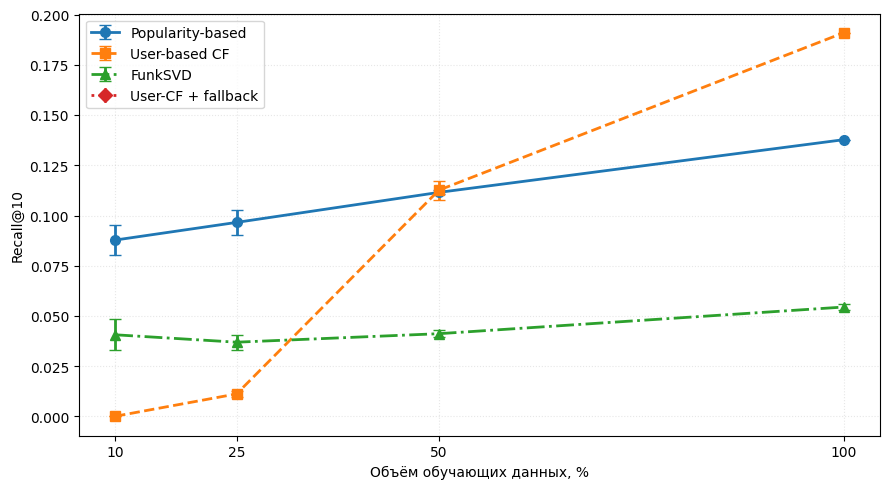

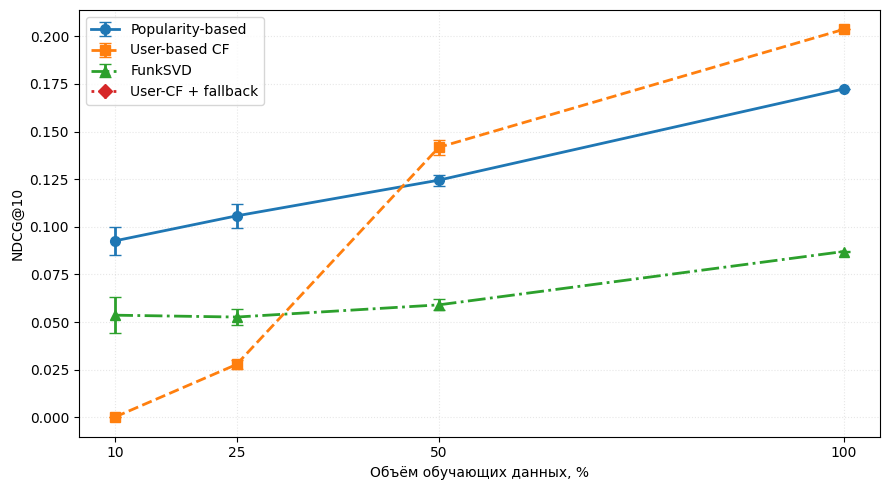

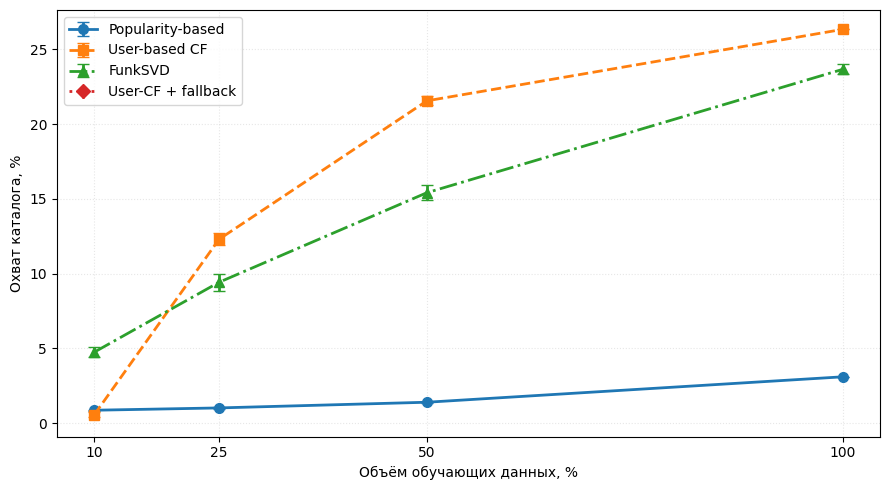

In [34]:

metrics = [
    ("Recall_mean", "Recall_std", "Recall@10"),
    ("NDCG_mean", "NDCG_std", "NDCG@10"),
    ("Coverage_mean", "Coverage_std", "Catalog Coverage")
]

algorithms = {
    "Popularity-based": {
        "marker": "o",
        "linestyle": "-"
    },
    "User-based CF": {
        "marker": "s",
        "linestyle": "--"
    },
    "FunkSVD": {
        "marker": "^",
        "linestyle": "-."
    },
    "User-CF + fallback": {
        "marker": "D",
        "linestyle": ":"
    }
}

for mean_col, std_col, metric_name in metrics:
    plt.figure(figsize=(9, 5))

    for algorithm, style in algorithms.items():
        data = summary_df[
            summary_df["Algorithm"] == algorithm
        ].sort_values("Data fraction")

        # Для Catalog Coverage переводим значения из долей в проценты
        multiplier = 100 if metric_name == "Catalog Coverage" else 1

        plt.errorbar(
            data["Data fraction"] * 100,
            data[mean_col] * multiplier,
            yerr=data[std_col] * multiplier,
            marker=style["marker"],
            linestyle=style["linestyle"],
            capsize=4,
            linewidth=2,
            markersize=7,
            label=algorithm
        )

    plt.xlabel("Объём обучающих данных, %")
    plt.ylabel(
        "Охват каталога, %"
        if metric_name == "Catalog Coverage"
        else metric_name
    )

    plt.xticks([10, 25, 50, 100])
    plt.grid(alpha=0.3, linestyle=":")
    plt.legend()
    plt.tight_layout()
    plt.show()


In [ ]:
print("Количество запусков:", len(results_df))
print("Количество пользователей:", len(eval_users))
print("Сохранены ли результаты рекомендаций:", "experiment_results" in globals())

print("\nСтолбцы результатов:")
print(results_df.columns.tolist())

Количество запусков: 60
Количество пользователей: 929
Сохранены ли результаты рекомендаций: True

Столбцы результатов:
['Data fraction', 'Repeat', 'Algorithm', 'Recall@10', 'NDCG@10', 'Catalog Coverage']


In [ ]:
from scipy.stats import wilcoxon
from itertools import combinations

statistical_results = []

algorithms = [
    "Popularity-based",
    "User-based CF",
    "FunkSVD"
]

metrics = ["Recall@10", "NDCG@10"]

for level in data_levels:

    level_data = results_df[
        results_df["Data fraction"] == level
    ]

    for metric in metrics:

        for algorithm_a, algorithm_b in combinations(algorithms, 2):

            values_a = (
                level_data[level_data["Algorithm"] == algorithm_a]
                .sort_values("Repeat")[metric]
                .values
            )

            values_b = (
                level_data[level_data["Algorithm"] == algorithm_b]
                .sort_values("Repeat")[metric]
                .values
            )

            statistic, p_value = wilcoxon(
                values_a,
                values_b,
                alternative="two-sided",
                method="exact"
            )

            statistical_results.append({
                "Data fraction": level,
                "Metric": metric,
                "Comparison": f"{algorithm_a} vs {algorithm_b}",
                "Wilcoxon statistic": statistic,
                "p-value": p_value
            })

wilcoxon_df = pd.DataFrame(statistical_results)

display(wilcoxon_df.round(5))

,Data fraction,Metric,Comparison,Wilcoxon statistic,p-value
0,0.10,Recall@10,Popularity-based vs User-based CF,0.0,0.0625
1,0.10,Recall@10,Popularity-based vs FunkSVD,0.0,0.0625
2,0.10,Recall@10,User-based CF vs FunkSVD,0.0,0.0625
3,0.10,NDCG@10,Popularity-based vs User-based CF,0.0,0.0625
4,0.10,NDCG@10,Popularity-based vs FunkSVD,0.0,0.0625
5,0.10,NDCG@10,User-based CF vs FunkSVD,0.0,0.0625
6,0.25,Recall@10,Popularity-based vs User-based CF,0.0,0.0625
7,0.25,Recall@10,Popularity-based vs FunkSVD,0.0,0.0625
8,0.25,Recall@10,User-based CF vs FunkSVD,0.0,0.0625
9,0.25,NDCG@10,Popularity-based vs User-based CF,0.0,0.0625


In [ ]:
from statsmodels.stats.multitest import multipletests

wilcoxon_df["p-value adjusted"] = multipletests(
    wilcoxon_df["p-value"],
    method="holm"
)[1]

wilcoxon_df["Significant"] = (
    wilcoxon_df["p-value adjusted"] < 0.05
)

display(wilcoxon_df.round(5))

,Data fraction,Metric,Comparison,Wilcoxon statistic,p-value,p-value adjusted,Significant
0,0.10,Recall@10,Popularity-based vs User-based CF,0.0,0.0625,1.0,False
1,0.10,Recall@10,Popularity-based vs FunkSVD,0.0,0.0625,1.0,False
2,0.10,Recall@10,User-based CF vs FunkSVD,0.0,0.0625,1.0,False
3,0.10,NDCG@10,Popularity-based vs User-based CF,0.0,0.0625,1.0,False
4,0.10,NDCG@10,Popularity-based vs FunkSVD,0.0,0.0625,1.0,False
5,0.10,NDCG@10,User-based CF vs FunkSVD,0.0,0.0625,1.0,False
6,0.25,Recall@10,Popularity-based vs User-based CF,0.0,0.0625,1.0,False
7,0.25,Recall@10,Popularity-based vs FunkSVD,0.0,0.0625,1.0,False
8,0.25,Recall@10,User-based CF vs FunkSVD,0.0,0.0625,1.0,False
9,0.25,NDCG@10,Popularity-based vs User-based CF,0.0,0.0625,1.0,False


In [ ]:
required_variables = [
    "ratings",
    "train_full",
    "test",
    "eval_users",
    "all_movies",
    "relevant_items",
    "experiment_datasets",
    "experiment_results",
    "results_df",
    "data_levels",
    "SEED"
]

for variable in required_variables:
    print(f"{variable}: {'OK' if variable in globals() else 'MISSING'}")

ratings: OK
train_full: OK
test: OK
eval_users: OK
all_movies: OK
relevant_items: OK
experiment_datasets: OK
experiment_results: OK
results_df: OK
data_levels: OK
SEED: OK


In [ ]:
import inspect

print("Функция reduce_training_data:")
print(inspect.signature(reduce_training_data))

print("\nКоличество уже созданных выборок:")
for level, datasets in experiment_datasets.items():
    print(f"{level}: {len(datasets)}")

Функция reduce_training_data:
(data, fraction, random_state)

Количество уже созданных выборок:
0.1: 5
0.25: 5
0.5: 5
1.0: 5


In [ ]:
 # Индивидуальные метрики для каждого пользователя

user_level_results = []

algorithms = [
    "Popularity-based",
    "User-based CF",
    "FunkSVD"
]

for level in data_levels:

    for repeat in range(n_repeats):

        print(
            f"\nДанные: {level:.0%} | "
            f"Повтор: {repeat + 1}/{n_repeats}"
        )

        train_data = experiment_datasets[level][repeat]

        # Формируем рекомендации
        recommendations = {
            "Popularity-based": run_popularity_experiment(train_data),

            "User-based CF": run_user_cf_experiment(
                train_data,
                k=20,
                min_neighbors=5
            ),

            "FunkSVD": run_svd_experiment(
                train_data,
                n_factors=50,
                learning_rate=0.01,
                regularization=0.02,
                epochs=20
            )
        }

        # Считаем метрики отдельно для каждого пользователя
        for algorithm, recs in recommendations.items():

            for user_id in eval_users:

                user_recs = recs[user_id]
                relevant = relevant_items[user_id]

                user_level_results.append({
                    "Data fraction": level,
                    "Repeat": repeat + 1,
                    "User ID": user_id,
                    "Algorithm": algorithm,

                    "Recall@10": calculate_recall(
                        user_recs,
                        relevant,
                        k=10
                    ),

                    "NDCG@10": calculate_ndcg(
                        user_recs,
                        relevant,
                        k=10
                    )
                })

# Сохраняем результаты
user_metrics_df = pd.DataFrame(user_level_results)

print("\nРасчёт завершён!")
print("Количество строк:", len(user_metrics_df))
print("Количество пользователей:", user_metrics_df["User ID"].nunique())

display(user_metrics_df.head())


Данные: 10% | Повтор: 1/5

Данные: 10% | Повтор: 2/5

Данные: 10% | Повтор: 3/5

Данные: 10% | Повтор: 4/5

Данные: 10% | Повтор: 5/5

Данные: 25% | Повтор: 1/5

Данные: 25% | Повтор: 2/5

Данные: 25% | Повтор: 3/5

Данные: 25% | Повтор: 4/5

Данные: 25% | Повтор: 5/5

Данные: 50% | Повтор: 1/5

Данные: 50% | Повтор: 2/5

Данные: 50% | Повтор: 3/5

Данные: 50% | Повтор: 4/5

Данные: 50% | Повтор: 5/5

Данные: 100% | Повтор: 1/5

Данные: 100% | Повтор: 2/5

Данные: 100% | Повтор: 3/5

Данные: 100% | Повтор: 4/5

Данные: 100% | Повтор: 5/5

Расчёт завершён!
Количество строк: 55740
Количество пользователей: 929


,Data fraction,Repeat,User ID,Algorithm,Recall@10,NDCG@10
0,0.1,1,1,Popularity-based,0.033333,0.220092
1,0.1,1,2,Popularity-based,0.500000,0.299749
2,0.1,1,3,Popularity-based,0.000000,0.000000
3,0.1,1,4,Popularity-based,0.500000,0.334246
4,0.1,1,5,Popularity-based,0.090909,0.085143


In [ ]:
# Усредняем индивидуальные метрики по пяти повторам

user_mean_metrics = (
    user_metrics_df
    .groupby(
        ["Data fraction", "User ID", "Algorithm"],
        as_index=False
    )
    [["Recall@10", "NDCG@10"]]
    .mean()
)

print("Количество строк:", len(user_mean_metrics))
print("Количество пользователей:", user_mean_metrics["User ID"].nunique())

display(user_mean_metrics.head(10))

Количество строк: 11148
Количество пользователей: 929


,Data fraction,User ID,Algorithm,Recall@10,NDCG@10
0,0.1,1,FunkSVD,0.013333,0.028930
1,0.1,1,Popularity-based,0.033333,0.134201
2,0.1,1,User-based CF,0.000000,0.000000
3,0.1,2,FunkSVD,0.033333,0.021558
4,0.1,2,Popularity-based,0.333333,0.217731
5,0.1,2,User-based CF,0.000000,0.000000
6,0.1,3,FunkSVD,0.080000,0.060157
7,0.1,3,Popularity-based,0.000000,0.000000
8,0.1,3,User-based CF,0.000000,0.000000
9,0.1,4,FunkSVD,0.050000,0.033626


In [ ]:
import numpy as np
import pandas as pd
from itertools import combinations
from scipy.stats import wilcoxon
from statsmodels.stats.multitest import multipletests

# ВАЖНО: подставь имя своей таблицы, где одна строка = (доля, пользователь, алгоритм),
# значения уже усреднены по 5 повторам (11 148 строк).
user_avg_df = user_mean_metrics

algorithms = ["Popularity-based", "User-based CF", "FunkSVD"]
metrics = ["Recall@10", "NDCG@10"]

rng = np.random.default_rng(42)


def bootstrap_ci(diff, n_boot=5000):
    """95% доверительный интервал для средней разницы (bootstrap по пользователям)."""
    idx = rng.integers(0, len(diff), size=(n_boot, len(diff)))
    means = diff[idx].mean(axis=1)
    return np.percentile(means, [2.5, 97.5])


rows = []

for frac in sorted(user_avg_df["Data fraction"].unique()):
    sub = user_avg_df[user_avg_df["Data fraction"] == frac]

    for metric in metrics:
        wide = sub.pivot(index="User ID", columns="Algorithm", values=metric)

        for a, b in combinations(algorithms, 2):
            diff = (wide[a] - wide[b]).to_numpy()

            # Если разница нулевая у всех пользователей, Вилкоксон не определён
            if np.allclose(diff, 0):
                p_value = 1.0
            else:
                p_value = wilcoxon(diff, alternative="two-sided").pvalue

            ci_low, ci_high = bootstrap_ci(diff)

            rows.append({
                "Data fraction": frac,
                "Metric": metric,
                "Comparison": f"{a} vs {b}",
                "Mean diff (A - B)": diff.mean(),
                "CI 95% low": ci_low,
                "CI 95% high": ci_high,
                "Users A better, %": (diff > 0).mean() * 100,
                "Users B better, %": (diff < 0).mean() * 100,
                "p-value": p_value,
            })

user_tests_df = pd.DataFrame(rows)

# Поправка Холма на все 24 сравнения сразу
user_tests_df["p-value adjusted"] = multipletests(
    user_tests_df["p-value"], method="holm"
)[1]
user_tests_df["Significant"] = user_tests_df["p-value adjusted"] < 0.05

display(user_tests_df.round(4))

user_tests_df.to_csv("nir_user_level_tests.csv", index=False, encoding="utf-8-sig")

,Data fraction,Metric,Comparison,Mean diff (A - B),CI 95% low,CI 95% high,"Users A better, %","Users B better, %",p-value,p-value adjusted,Significant
0,0.10,Recall@10,Popularity-based vs User-based CF,0.0877,0.0799,0.0956,70.5059,0.1076,0.0000,0.0000,True
1,0.10,Recall@10,Popularity-based vs FunkSVD,0.0471,0.0392,0.0553,50.0538,27.5565,0.0000,0.0000,True
2,0.10,Recall@10,User-based CF vs FunkSVD,-0.0406,-0.0441,-0.0370,0.1076,62.5404,0.0000,0.0000,True
3,0.10,NDCG@10,Popularity-based vs User-based CF,0.0924,0.0858,0.0989,70.2906,0.3229,0.0000,0.0000,True
4,0.10,NDCG@10,Popularity-based vs FunkSVD,0.0390,0.0320,0.0458,50.9150,32.2928,0.0000,0.0000,True
5,0.10,NDCG@10,User-based CF vs FunkSVD,-0.0534,-0.0574,-0.0494,0.2153,62.5404,0.0000,0.0000,True
6,0.25,Recall@10,Popularity-based vs User-based CF,0.0854,0.0772,0.0941,61.5716,7.4273,0.0000,0.0000,True
7,0.25,Recall@10,Popularity-based vs FunkSVD,0.0596,0.0506,0.0690,50.6997,25.2960,0.0000,0.0000,True
8,0.25,Recall@10,User-based CF vs FunkSVD,-0.0257,-0.0293,-0.0222,11.8407,48.7621,0.0000,0.0000,True
9,0.25,NDCG@10,Popularity-based vs User-based CF,0.0780,0.0706,0.0855,59.3111,12.3789,0.0000,0.0000,True


In [ ]:
# Описательная статистика по пользовательским метрикам

descriptive_user_results = (
    user_mean_metrics
    .groupby(["Data fraction", "Algorithm"])
    [["Recall@10", "NDCG@10"]]
    .agg(["mean", "std"])
    .round(4)
)

display(descriptive_user_results)

Recall@10         NDCG@10        
                                    mean     std    mean     std
Data fraction Algorithm                                         
0.10          FunkSVD             0.0407  0.0538  0.0536  0.0621
              Popularity-based    0.0878  0.1215  0.0927  0.1022
              User-based CF       0.0001  0.0014  0.0003  0.0034
0.25          FunkSVD             0.0370  0.0522  0.0527  0.0697
              Popularity-based    0.0966  0.1361  0.1058  0.1208
              User-based CF       0.0112  0.0222  0.0278  0.0456
0.50          FunkSVD             0.0412  0.0578  0.0591  0.0740
              Popularity-based    0.1115  0.1530  0.1245  0.1402
              User-based CF       0.1126  0.1086  0.1417  0.1124
1.00          FunkSVD             0.0545  0.0705  0.0870  0.1134
              Popularity-based    0.1377  0.1609  0.1724  0.1763
              User-based CF       0.1909  0.2241  0.2036  0.1883

In [ ]:
def run_user_cf_with_fallback(train_data, k=20, min_neighbors=5):

    # Получаем рекомендации User-based CF
    cf_recommendations = run_user_cf_experiment(
        train_data,
        k=k,
        min_neighbors=min_neighbors
    )

    # Формируем рейтинг популярности на текущей обучающей выборке
    popularity = (
        train_data.groupby("movie_id")
        .agg(
            rating_count=("rating", "count"),
            average_rating=("rating", "mean")
        )
        .reset_index()
    )

    popularity = popularity.sort_values(
        by=["rating_count", "average_rating", "movie_id"],
        ascending=[False, False, True]
    )

    popularity_ranking = popularity["movie_id"].tolist()

    recommendations = {}

    for user_id in eval_users:

        # Рекомендации User-CF
        cf_list = cf_recommendations.get(user_id, [])

        # Исключаем уже оценённые фильмы
        seen_movies = set(
            train_data.loc[
                train_data["user_id"] == user_id,
                "movie_id"
            ]
        )

        # Сохраняем рекомендации CF
        final_list = list(cf_list)

        # Если рекомендаций меньше 10 — дополняем популярными фильмами
        if len(final_list) < 10:

            for movie_id in popularity_ranking:

                if movie_id not in seen_movies and movie_id not in final_list:
                    final_list.append(int(movie_id))

                if len(final_list) == 10:
                    break

        recommendations[user_id] = final_list[:10]

    return recommendations


print("Функция User-CF + Popularity fallback готова!")

Функция User-CF + Popularity fallback готова!


In [ ]:
test_recommendations = run_user_cf_with_fallback(
    experiment_datasets[0.10][0]
)

empty_count = sum(
    len(recs) == 0
    for recs in test_recommendations.values()
)

short_count = sum(
    len(recs) < 10
    for recs in test_recommendations.values()
)

full_count = sum(
    len(recs) == 10
    for recs in test_recommendations.values()
)

print(f"Пользователей в тесте: {len(test_recommendations)}")
print(f"Пустые списки: {empty_count}")
print(f"Неполные списки (1–9 фильмов): {short_count}")
print(f"Полные списки (10 фильмов): {full_count}")

Пользователей в тесте: 929
Пустые списки: 0
Неполные списки (1–9 фильмов): 0
Полные списки (10 фильмов): 929


In [ ]:
# ============================================================
# ЯЧЕЙКА 1. Запускаем ТОЛЬКО новый метод на всех 4 долях x 5 повторов
# (функцию run_user_cf_with_fallback ты уже определила выше)
# ============================================================
ALGO_NAME = "User-CF + fallback"

fallback_rows = []        # метрики по каждому запуску (для сводной таблицы)
fallback_user_rows = []   # метрики по каждому пользователю (для тестов)
fallback_stats = []       # сколько пользователей получили неполный список от чистого CF

for level in data_levels:
    for repeat in range(n_repeats):
        train_data = experiment_datasets[level][repeat]

        # Сколько пользователей чистый User-CF оставил с неполным списком
        cf_only = run_user_cf_experiment(train_data)
        incomplete_share = np.mean([len(cf_only[u]) < 10 for u in eval_users])
        fallback_stats.append({
            "Data fraction": level,
            "Repeat": repeat + 1,
            "Share of users with incomplete CF list": incomplete_share
        })

        # Новый метод
        recs = run_user_cf_with_fallback(train_data)

        metrics = evaluate_recommendations(recs)
        fallback_rows.append({
            "Data fraction": level,
            "Repeat": repeat + 1,
            "Algorithm": ALGO_NAME,
            **metrics
        })

        for user_id in eval_users:
            fallback_user_rows.append({
                "Data fraction": level,
                "Repeat": repeat + 1,
                "User ID": user_id,
                "Algorithm": ALGO_NAME,
                "Recall@10": calculate_recall(recs[user_id], relevant_items[user_id]),
                "NDCG@10": calculate_ndcg(recs[user_id], relevant_items[user_id]),
            })

        print(f"Готово: {int(level * 100)}% данных, повтор {repeat + 1}")

fallback_results_df = pd.DataFrame(fallback_rows)
fallback_user_df = pd.DataFrame(fallback_user_rows)
fallback_stats_df = pd.DataFrame(fallback_stats)

# Доля пользователей, которым чистый CF не смог выдать 10 рекомендаций
# (эту таблицу стоит привести в отчёте)
display(
    fallback_stats_df
    .groupby("Data fraction")["Share of users with incomplete CF list"]
    .mean()
    .round(3)
)


# ============================================================
# ЯЧЕЙКА 2. Объединяем с уже посчитанными результатами
# ВАЖНО: подставь имена СВОИХ таблиц вместо двух строк со стрелками
# ============================================================
results_df_all = pd.concat(
    [results_df, fallback_results_df], ignore_index=True
)

# Усредняем пользовательские метрики по 5 повторам (как для остальных методов)
fallback_user_avg = (
    fallback_user_df
    .groupby(["Data fraction", "User ID", "Algorithm"], as_index=False)
    [["Recall@10", "NDCG@10"]]
    .mean()
)

user_avg_df_all = pd.concat(
    [user_mean_metrics, fallback_user_avg],
    ignore_index=True
)

# Сводная таблица по повторам (mean и std по 5 запускам)
summary_all = (
    results_df_all
    .groupby(["Data fraction", "Algorithm"])
    [["Recall@10", "NDCG@10", "Catalog Coverage"]]
    .agg(["mean", "std"])
    .round(4)
)
display(summary_all)

# Дальше: в скрипте user_level_tests.py замени две строки
#   user_avg_df = user_avg_df_all
#   algorithms = ["Popularity-based", "User-based CF", "FunkSVD", "User-CF + fallback"]
# и запусти его снова. Сравнений станет 48 (6 пар x 2 метрики x 4 доли).

Готово: 10% данных, повтор 1
Готово: 10% данных, повтор 2
Готово: 10% данных, повтор 3
Готово: 10% данных, повтор 4
Готово: 10% данных, повтор 5
Готово: 25% данных, повтор 1
Готово: 25% данных, повтор 2
Готово: 25% данных, повтор 3
Готово: 25% данных, повтор 4
Готово: 25% данных, повтор 5
Готово: 50% данных, повтор 1
Готово: 50% данных, повтор 2
Готово: 50% данных, повтор 3
Готово: 50% данных, повтор 4
Готово: 50% данных, повтор 5
Готово: 100% данных, повтор 1
Готово: 100% данных, повтор 2
Готово: 100% данных, повтор 3
Готово: 100% данных, повтор 4
Готово: 100% данных, повтор 5


,Share of users with incomplete CF list
Data fraction,
0.10,1.000
0.25,0.990
0.50,0.383
1.00,0.001


Recall@10         NDCG@10          \
                                      mean     std    mean     std   
Data fraction Algorithm                                              
0.10          FunkSVD               0.0407  0.0077  0.0536  0.0094   
              Popularity-based      0.0878  0.0075  0.0927  0.0074   
              User-CF + fallback    0.0877  0.0074  0.0927  0.0073   
              User-based CF         0.0001  0.0001  0.0003  0.0002   
0.25          FunkSVD               0.0370  0.0037  0.0527  0.0040   
              Popularity-based      0.0966  0.0061  0.1058  0.0064   
              User-CF + fallback    0.0981  0.0055  0.1077  0.0046   
              User-based CF         0.0112  0.0016  0.0278  0.0022   
0.50          FunkSVD               0.0412  0.0018  0.0591  0.0028   
              Popularity-based      0.1115  0.0010  0.1245  0.0029   
              User-CF + fallback    0.1335  0.0038  0.1532  0.0035   
              User-based CF         0.1126  0.0048  0.1417  0.0040   
1.00          FunkSVD               0.0545  0.0016  0.0870  0.0004   
              Popularity-based      0.1377  0.0000  0.1724  0.0000   
              User-CF + fallback    0.1909  0.0000  0.2036  0.0000   
              User-based CF         0.1909  0.0000  0.2036  0.0000   

                                 Catalog Coverage          
                                             mean     std  
Data fraction Algorithm                                    
0.10          FunkSVD                      0.0474  0.0031  
              Popularity-based             0.0086  0.0003  
              User-CF + fallback           0.0114  0.0013  
              User-based CF                0.0056  0.0017  
0.25          FunkSVD                      0.0942  0.0056  
              Popularity-based             0.0101  0.0004  
              User-CF + fallback           0.1229  0.0040  
              User-based CF                0.1229  0.0040  
0.50          FunkSVD                      0.1541  0.0051  
              Popularity-based             0.0139  0.0003  
              User-CF + fallback           0.2156  0.0030  
              User-based CF                0.2156  0.0030  
1.00          FunkSVD                      0.2366  0.0034  
              Popularity-based             0.0309  0.0000  
              User-CF + fallback           0.2634  0.0000  
              User-based CF                0.2634  0.0000

In [ ]:
for name, value in globals().copy().items():
    if isinstance(value, pd.DataFrame):
        print(f"\n{name}: {value.shape}")
        print("Столбцы:", list(value.columns))


_: (5, 4)
Столбцы: ['user_id', 'movie_id', 'rating', 'timestamp']

ratings: (100000, 4)
Столбцы: ['user_id', 'movie_id', 'rating', 'timestamp']

_5: (5, 4)
Столбцы: ['user_id', 'movie_id', 'rating', 'timestamp']

user_data: (134, 4)
Столбцы: ['user_id', 'movie_id', 'rating', 'timestamp']

user_train: (107, 4)
Столбцы: ['user_id', 'movie_id', 'rating', 'timestamp']

user_test: (34, 4)
Столбцы: ['user_id', 'movie_id', 'rating', 'timestamp']

train_full: (79619, 4)
Столбцы: ['user_id', 'movie_id', 'rating', 'timestamp']

test: (20381, 4)
Столбцы: ['user_id', 'movie_id', 'rating', 'timestamp']

relevant_test: (11270, 4)
Столбцы: ['user_id', 'movie_id', 'rating', 'timestamp']

movie_popularity: (1650, 3)
Столбцы: ['movie_id', 'rating_count', 'average_rating']

user_validation: (27, 4)
Столбцы: ['user_id', 'movie_id', 'rating', 'timestamp']

tune_train: (63305, 4)
Столбцы: ['user_id', 'movie_id', 'rating', 'timestamp']

validation: (16314, 4)
Столбцы: ['user_id', 'movie_id', 'rating', 'time

In [ ]:
import numpy as np
import pandas as pd
from itertools import combinations
from scipy.stats import wilcoxon
from statsmodels.stats.multitest import multipletests

# Таблица, которую ты уже собрала в прошлой ячейке (14864 строки, 4 алгоритма)
df_for_tests = user_avg_df_all

algorithms = ["Popularity-based", "User-based CF", "FunkSVD", "User-CF + fallback"]
metrics = ["Recall@10", "NDCG@10"]

rng = np.random.default_rng(42)


def bootstrap_ci(diff, n_boot=5000):
    idx = rng.integers(0, len(diff), size=(n_boot, len(diff)))
    means = diff[idx].mean(axis=1)
    return np.percentile(means, [2.5, 97.5])


rows = []

for frac in sorted(df_for_tests["Data fraction"].unique()):
    sub = df_for_tests[df_for_tests["Data fraction"] == frac]

    for metric in metrics:
        wide = sub.pivot(index="User ID", columns="Algorithm", values=metric)

        for a, b in combinations(algorithms, 2):
            diff = (wide[a] - wide[b]).to_numpy()

            if np.allclose(diff, 0):
                p_value = 1.0
            else:
                p_value = wilcoxon(diff, alternative="two-sided").pvalue

            ci_low, ci_high = bootstrap_ci(diff)

            rows.append({
                "Data fraction": frac,
                "Metric": metric,
                "Comparison": f"{a} vs {b}",
                "Mean diff (A - B)": diff.mean(),
                "CI 95% low": ci_low,
                "CI 95% high": ci_high,
                "Users A better, %": (diff > 0).mean() * 100,
                "Users B better, %": (diff < 0).mean() * 100,
                "p-value": p_value,
            })

user_tests_all_df = pd.DataFrame(rows)

# Поправка Холма на все 48 сравнений сразу
user_tests_all_df["p-value adjusted"] = multipletests(
    user_tests_all_df["p-value"], method="holm"
)[1]
user_tests_all_df["Significant"] = user_tests_all_df["p-value adjusted"] < 0.05

print("Всего сравнений:", len(user_tests_all_df))
display(user_tests_all_df.round(4))

user_tests_all_df.to_csv("nir_user_level_tests_4alg.csv", index=False, encoding="utf-8-sig")

Всего сравнений: 48


,Data fraction,Metric,Comparison,Mean diff (A - B),CI 95% low,CI 95% high,"Users A better, %","Users B better, %",p-value,p-value adjusted,Significant
0,0.10,Recall@10,Popularity-based vs User-based CF,0.0877,0.0799,0.0956,70.5059,0.1076,0.0000,0.0000,True
1,0.10,Recall@10,Popularity-based vs FunkSVD,0.0471,0.0392,0.0553,50.0538,27.5565,0.0000,0.0000,True
2,0.10,Recall@10,Popularity-based vs User-CF + fallback,0.0001,-0.0001,0.0003,0.4306,0.3229,0.3980,1.0000,False
3,0.10,Recall@10,User-based CF vs FunkSVD,-0.0406,-0.0441,-0.0372,0.1076,62.5404,0.0000,0.0000,True
4,0.10,Recall@10,User-based CF vs User-CF + fallback,-0.0876,-0.0954,-0.0800,0.0000,70.5059,0.0000,0.0000,True
5,0.10,Recall@10,FunkSVD vs User-CF + fallback,-0.0470,-0.0551,-0.0394,27.5565,50.0538,0.0000,0.0000,True
6,0.10,NDCG@10,Popularity-based vs User-based CF,0.0924,0.0859,0.0991,70.2906,0.3229,0.0000,0.0000,True
7,0.10,NDCG@10,Popularity-based vs FunkSVD,0.0390,0.0324,0.0460,50.9150,32.2928,0.0000,0.0000,True
8,0.10,NDCG@10,Popularity-based vs User-CF + fallback,-0.0000,-0.0003,0.0002,1.5070,0.5382,0.6580,1.0000,False
9,0.10,NDCG@10,User-based CF vs FunkSVD,-0.0534,-0.0574,-0.0494,0.2153,62.5404,0.0000,0.0000,True
